In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.polynomial import Polynomial
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
VALIDATION_SIZE = 0.2
ITERATIONS = 5000
FEATURES = ["AT", "V", "AP", "RH"]
TARGET = "PE"

candidates = [Path.cwd(), Path.cwd() / "Lab Works" / "Lab-2"]
DATA_DIR = next((p for p in candidates if (p / "data_02b.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Start the kernel in Lab Works/Lab-2 or the repository root.")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
print("Data directory:", DATA_DIR.resolve())


Data directory: D:\CSE-4125-ML\Lab Works\Lab-2


## Linear Regression with Multiple Variables

In [10]:
def add_bias(features):
    return np.column_stack((np.ones(len(features)), features))


def mse(actual, predicted):
    return float(np.mean((actual - predicted) ** 2))


def gradient_descent(x_train, y_train, x_valid, y_valid, iterations=ITERATIONS):
    'Fit linear weights and retain the best validation checkpoint.'
    train_matrix, valid_matrix = add_bias(x_train), add_bias(x_valid)
    gram = train_matrix.T @ train_matrix / len(y_train)
    cross = train_matrix.T @ y_train / len(y_train)
    learning_rate = 0.9 / (2 * np.linalg.eigvalsh(gram)[-1])
    weights = np.zeros(train_matrix.shape[1])
    weights[0] = y_train.mean()
    train_curve, valid_curve = [], []
    best_error = np.inf

    for iteration in range(iterations + 1):
        train_error = mse(y_train, train_matrix @ weights)
        valid_error = mse(y_valid, valid_matrix @ weights)
        if not np.isfinite(train_error + valid_error):
            raise FloatingPointError("Gradient descent produced non-finite errors.")
        train_curve.append(train_error)
        valid_curve.append(valid_error)
        if valid_error < best_error:
            best_error = valid_error
            best_weights = weights.copy()
            best_iteration = iteration
            best_train_error = train_error
        if iteration < iterations:
            # Equivalent to 2 * X.T @ (X @ weights - y) / n.
            weights -= learning_rate * 2 * (gram @ weights - cross)

    return {
        "best_weights": best_weights,
        "best_iteration": best_iteration,
        "train_error": best_train_error,
        "valid_error": best_error,
        "train_curve": np.array(train_curve),
        "valid_curve": np.array(valid_curve),
        "learning_rate": learning_rate,
    }


def error_table(models):
    'Summarize errors at the selected checkpoint for each model.'
    return pd.DataFrame([
        {"Model": name, "Training MSE": model["train_error"],
         "Validation MSE": model["valid_error"],
         "Best iteration": model["best_iteration"],
         "Learning rate": model["learning_rate"]}
        for name, model in models.items()
    ]).set_index("Model")


def plot_learning_curves(models):
    'Show one training/validation learning-curve panel per model.'
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)
    for axis, (name, model) in zip(axes.flat, models.items()):
        axis.plot(model["train_curve"], label="Training")
        axis.plot(model["valid_curve"], label="Validation")
        axis.axvline(model["best_iteration"], color="gray", linestyle=":", label="Best iteration")
        axis.set(xlabel="Iteration", ylabel="MSE", title=str(name))
        axis.legend()
    fig.tight_layout()
    plt.show()


Observations: 9568; features: 4; target: PE


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


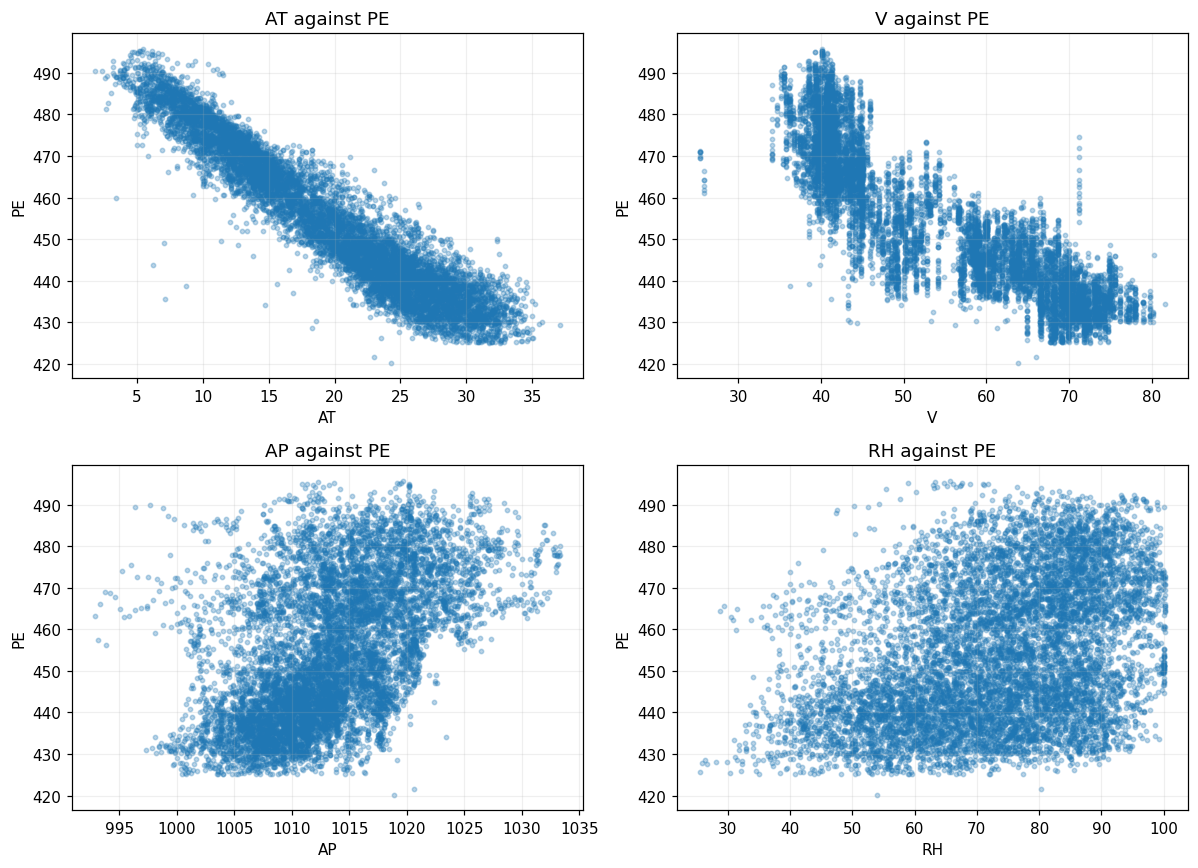

In [11]:
def load_power_plant_data():
    paths = [DATA_DIR / "data_02a.xlsx", DATA_DIR / "CCPP" / "CCPP" / "Folds5x2_pp.xlsx"]
    path = next((p for p in paths if p.is_file()), None)
    if path is None:
        raise FileNotFoundError("The CCPP Excel workbook is missing.")
    data = pd.read_excel(path, sheet_name=0)
    data.columns = data.columns.astype(str).str.strip()
    data = data[FEATURES + [TARGET]].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(data.to_numpy()).all():
        raise ValueError("CCPP data contain missing or non-finite values.")
    if len(data) != 9568:
        raise ValueError(f"Expected 9568 observations, found {len(data)}.")
    return data


power_data = load_power_plant_data()
print(f"Observations: {len(power_data)}; features: {len(FEATURES)}; target: {TARGET}")
display(power_data.head())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, feature in zip(axes.flat, FEATURES):
    axis.scatter(power_data[feature], power_data[TARGET], s=8, alpha=0.3)
    axis.set(xlabel=feature, ylabel=TARGET, title=f"{feature} against {TARGET}")
fig.tight_layout()
plt.show()


Training samples: 7654; validation samples: 1914


,Training MSE,Validation MSE,Best iteration,Learning rate
Model,,,,
Unscaled,80.808539,79.760306,5000,0.000000
Standardized,20.903570,20.263773,90,0.184434


Learned parameters in original feature units:


,Unscaled,Standardized
Intercept,454.430901,446.737798
AT,-0.342451,-1.953382
V,-0.516392,-0.246207
AP,0.021542,0.069662
RH,0.176376,-0.152697


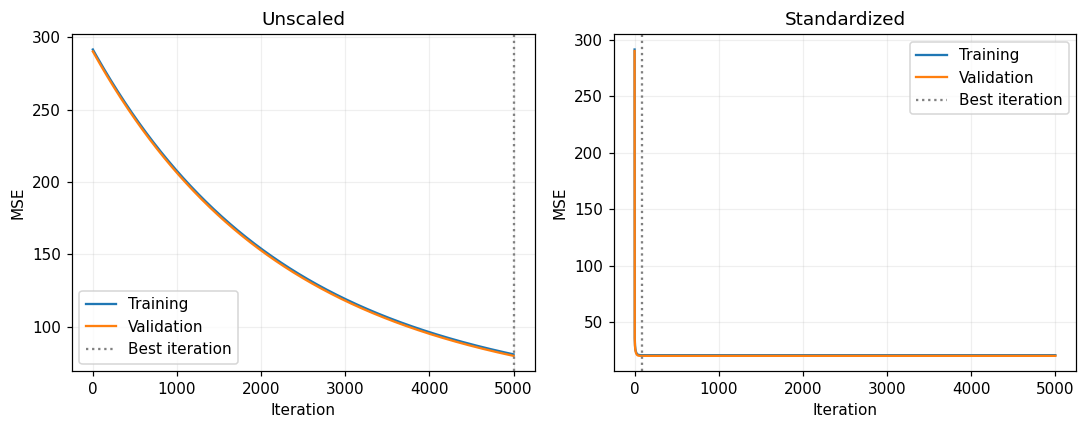

Validation MSE: unscaled = 79.760306; standardized = 20.263773
Reduction after scaling: 74.59%


In [12]:
def fit_linear(x_train, y_train, x_valid, y_valid, scale=False):
    'Optionally standardize using training statistics, then fit weights.'
    scaler = StandardScaler() if scale else None
    if scaler is not None:
        x_train = scaler.fit_transform(x_train)
        x_valid = scaler.transform(x_valid)
    model = gradient_descent(x_train, y_train, x_valid, y_valid)
    model["scaler"] = scaler
    return model


def linear_parameters(model):
    'Return intercept and slopes in the original feature units.'
    weights = model["best_weights"].copy()
    scaler = model["scaler"]
    if scaler is not None:
        weights[1:] /= scaler.scale_
        weights[0] -= scaler.mean_ @ weights[1:]
    return weights


x_train_a, x_valid_a, y_train_a, y_valid_a = train_test_split(
    power_data[FEATURES].to_numpy(dtype=float), power_data[TARGET].to_numpy(dtype=float),
    test_size=VALIDATION_SIZE, random_state=SEED,
)
linear_models = {
    "Unscaled": fit_linear(x_train_a, y_train_a, x_valid_a, y_valid_a),
    "Standardized": fit_linear(x_train_a, y_train_a, x_valid_a, y_valid_a, scale=True),
}
print(f"Training samples: {len(y_train_a)}; validation samples: {len(y_valid_a)}")
display(error_table(linear_models).style.format(precision=6))
print("Learned parameters in original feature units:")
linear_coefficients = pd.DataFrame(
    {name: linear_parameters(model) for name, model in linear_models.items()},
    index=["Intercept"] + FEATURES,
)
display(linear_coefficients.style.format(precision=6))
plot_learning_curves(linear_models)

raw_error = linear_models["Unscaled"]["valid_error"]
scaled_error = linear_models["Standardized"]["valid_error"]
print(f"Validation MSE: unscaled = {raw_error:.6f}; standardized = {scaled_error:.6f}")
print(f"Reduction after scaling: {100 * (raw_error - scaled_error) / raw_error:.2f}%")


## Polynomial Regression

Observations: 392


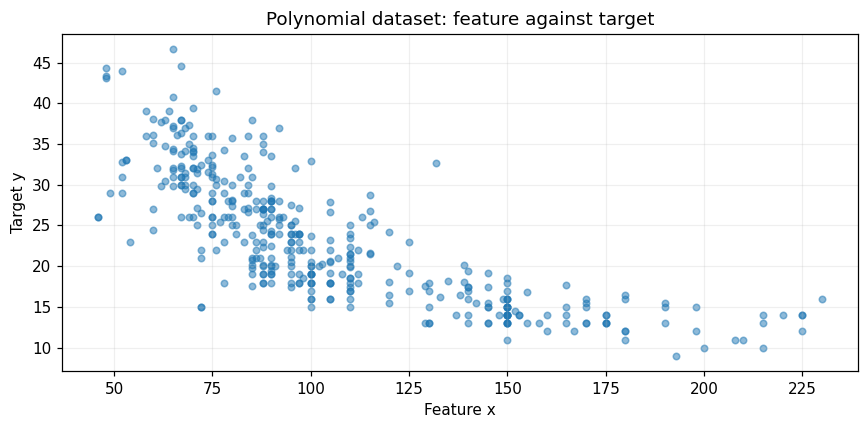

In [13]:
def load_polynomial_data():
    'Read the supplied headerless feature/target CSV without losing row one.'
    data = pd.read_csv(DATA_DIR / "data_02b.csv", header=None)
    if data.shape[1] != 2:
        raise ValueError("Expected exactly two columns: feature and target.")
    values = data.apply(pd.to_numeric, errors="raise").to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Polynomial data contain missing or non-finite values.")
    return values[:, :1], values[:, 1]


x_b, y_b = load_polynomial_data()
print(f"Observations: {len(y_b)}")
plt.figure(figsize=(8, 4))
plt.scatter(x_b[:, 0], y_b, s=18, alpha=0.5)
plt.xlabel("Feature x")
plt.ylabel("Target y")
plt.title("Polynomial dataset: feature against target")
plt.tight_layout()
plt.show()


In [14]:
def fit_polynomial(x_train, y_train, x_valid, y_valid, degree):
    'Create polynomial features and fit using the shared gradient descent.'
    scaler = StandardScaler()
    polynomial = PolynomialFeatures(degree=degree, include_bias=False)
    train_features = polynomial.fit_transform(scaler.fit_transform(x_train))
    valid_features = polynomial.transform(scaler.transform(x_valid))
    model = gradient_descent(train_features, y_train, valid_features, y_valid)
    model.update(scaler=scaler, polynomial=polynomial)
    return model


def polynomial_predict(model, x):
    'Apply the fitted preprocessing and predict targets.'
    features = model["polynomial"].transform(model["scaler"].transform(x))
    return add_bias(features) @ model["best_weights"]


def polynomial_parameters(model):
    'Expand the learned polynomial into coefficients of the original x.'
    scaler = model["scaler"]
    standardized_x = Polynomial([-scaler.mean_[0] / scaler.scale_[0], 1 / scaler.scale_[0]])
    return Polynomial(model["best_weights"])(standardized_x).coef


x_train_b, x_valid_b, y_train_b, y_valid_b = train_test_split(
    x_b, y_b, test_size=VALIDATION_SIZE, random_state=SEED,
)
polynomial_models = {
    degree: fit_polynomial(x_train_b, y_train_b, x_valid_b, y_valid_b, degree)
    for degree in (1, 2, 3)
}
print(f"Training samples: {len(y_train_b)}; validation samples: {len(y_valid_b)}")
display(error_table(polynomial_models).rename_axis("Degree").style.format(precision=6))


Training samples: 313; validation samples: 79


,Training MSE,Validation MSE,Best iteration,Learning rate
Degree,,,,
1,24.861414,21.424804,1,0.450000
2,19.293249,18.337718,34,0.107616
3,19.310852,18.308675,189,0.017236


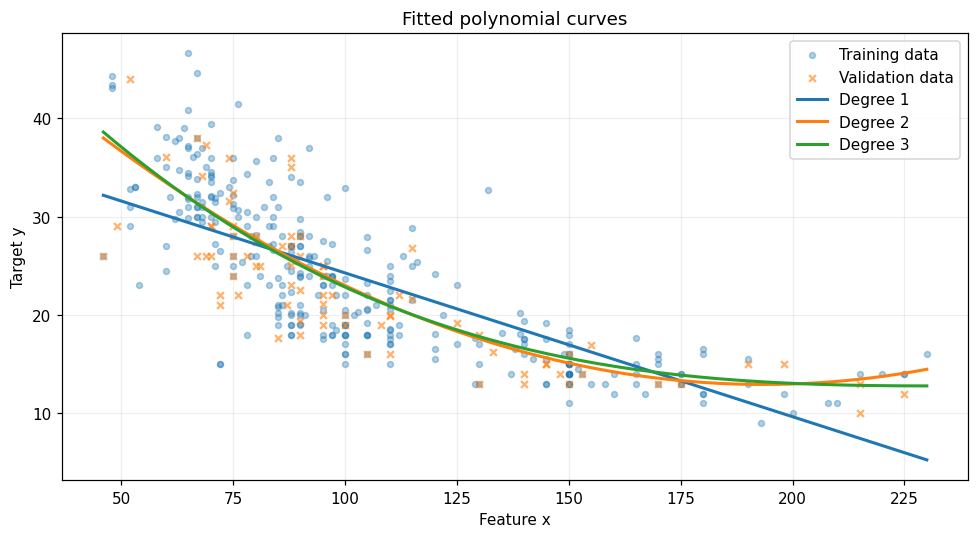

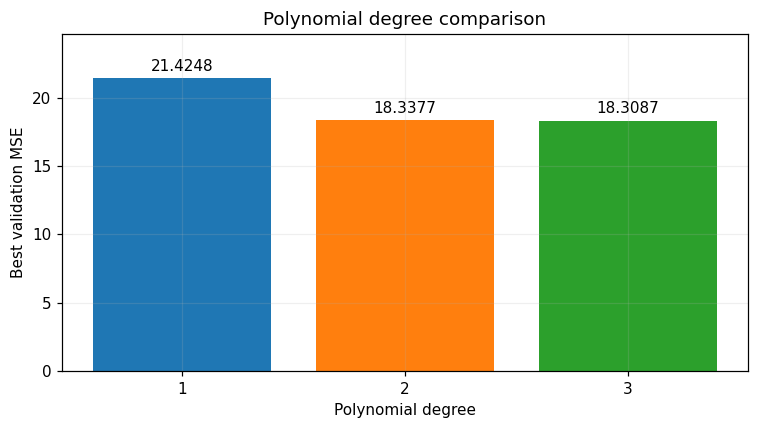

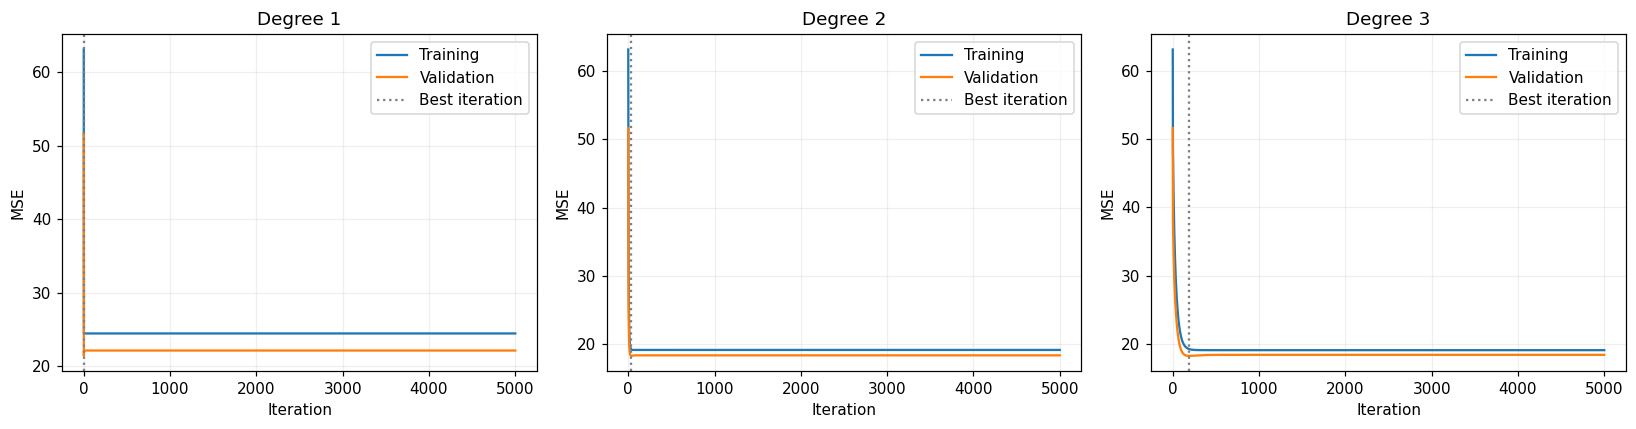

In [15]:
x_line = np.linspace(x_b.min(), x_b.max(), 300).reshape(-1, 1)
fig, axis = plt.subplots(figsize=(9, 5))
axis.scatter(x_train_b[:, 0], y_train_b, s=15, alpha=0.35, label="Training data")
axis.scatter(x_valid_b[:, 0], y_valid_b, s=20, alpha=0.6, marker="x", label="Validation data")
for degree, model in polynomial_models.items():
    axis.plot(x_line[:, 0], polynomial_predict(model, x_line), linewidth=2, label=f"Degree {degree}")
axis.set(xlabel="Feature x", ylabel="Target y", title="Fitted polynomial curves")
axis.legend()
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(7, 4))
bars = axis.bar(
    [str(degree) for degree in polynomial_models],
    [model["valid_error"] for model in polynomial_models.values()],
    color=["tab:blue", "tab:orange", "tab:green"],
)
axis.bar_label(bars, fmt="%.4f", padding=3)
axis.margins(y=0.15)
axis.set(xlabel="Polynomial degree", ylabel="Best validation MSE", title="Polynomial degree comparison")
fig.tight_layout()
plt.show()

plot_learning_curves({f"Degree {degree}": model for degree, model in polynomial_models.items()})


In [16]:
best_degree = min(polynomial_models, key=lambda degree: polynomial_models[degree]["valid_error"])
best_model = polynomial_models[best_degree]
coefficients = polynomial_parameters(best_model)

print(f"Best polynomial degree: {best_degree}")
print(f"Best iteration: {best_model['best_iteration']}")
print(f"Training MSE: {best_model['train_error']:.6f}")
print(f"Validation MSE: {best_model['valid_error']:.6f}")
display(pd.DataFrame({"Parameter": [f"Coefficient of x^{i}" for i in range(len(coefficients))],
                      "Original-unit value": coefficients}).style.format({"Original-unit value": "{:.8f}"}))
equation = f"y_hat = {coefficients[0]:.8f}"
for power, coefficient in enumerate(coefficients[1:], start=1):
    equation += f" {coefficient:+.8f} * x^{power}"
print("Selected hypothesis in original feature units:")
print(equation)
print(f"Degree {best_degree} is selected because it has the lowest validation MSE among 1, 2, and 3.")


Best polynomial degree: 3
Best iteration: 189
Training MSE: 19.310852
Validation MSE: 18.308675


,Parameter,Original-unit value
0,Coefficient of x^0,60.71775755
1,Coefficient of x^1,-0.58178807
2,Coefficient of x^2,0.00234120
3,Coefficient of x^3,-0.00000312


Selected hypothesis in original feature units:
y_hat = 60.71775755 -0.58178807 * x^1 +0.00234120 * x^2 -0.00000312 * x^3
Degree 3 is selected because it has the lowest validation MSE among 1, 2, and 3.
